Luis Anunciacao, PhD
2026-10-15 - 17:30

# DA - AGEM Time Series

Loads `df.rds` from the DP notebook. Nothing is transformed here. Headers match the report's tables; one table per instrument and company.

**Columns.** Counts by wave (header: respondents per wave); "—" = item not applied in that wave. Items sorted by p.

**Tests (exploratory, no adjustment for multiplicity).** Scale items only, on the 5-point `test_value`. Waves are independent samples: SurveyMonkey collected no respondent ID, so answers cannot be paired.
Three waves: Kruskal-Wallis test; when p < .05, post hoc pairwise Wilcoxon rank-sum tests, unadjusted (protected by the omnibus test, Fisher LSD logic).
Two waves: Wilcoxon rank-sum test (Mann-Whitney U). Post hoc lists the waves that differ (p < .05), ordered by mean score.

**Items.** Stable items only (DP §3): 8 lideres items (T1-T3) and 38 emocional items (T1-T2); items reworded, negated or not asked in some wave are excluded.

**Tables 3-4.** Scale responses collapsed to 3 categories (DP §3); risk items flagged "(risco)"; the questionnaire's own "(invertida)" tags are dropped.

## Packages and data

In [1]:
pacman::p_load(tidyverse)

options(repr.matrix.max.rows = 400, repr.matrix.max.cols = 20)

# DP output from GitHub (Processing and analysis/Importable data/df.rds); private repository, token from the git credential store (gitcreds)
df <- readRDS(gzcon(curl::curl("https://raw.githubusercontent.com/anovabr/AGEM-Time-Series/main/Processing%20and%20analysis/Importable%20data/df.rds",
                               handle = curl::new_handle() |> curl::handle_setheaders(Authorization = paste("token", gitcreds::gitcreds_get()$password)))))

In [2]:
# APA-style table for one instrument and company: item, response, counts by wave, omnibus p (Kruskal-Wallis for 3 waves,
# rank-sum for 2) and post hoc; collapse = TRUE counts the 3-category responses and flags risk items
freq_table <- function(inst, comp, collapse = FALSE) {
  d <- filter(df, instrument == inst, company == comp) |> mutate(code = if (collapse) code_3 else code)
  attr(df, "options") |>
    filter(instrument == inst) |>
    transmute(item, code = if (collapse) code_3 else code, response = if (collapse) response_3 else response) |>
    distinct() |>
    inner_join(distinct(d, item, wave), by = "item", relationship = "many-to-many") |>
    left_join(count(d, item, code, wave), by = c("item", "code", "wave")) |>
    mutate(n = as.character(replace_na(n, 0L))) |>
    pivot_wider(names_from = wave, values_from = n, values_fill = "—", names_sort = TRUE) |>
    left_join(d |>
                filter(!is.na(test_value)) |>
                filter(n_distinct(wave) > 1, .by = item) |>
                summarise(p = if (n_distinct(wave) > 2) kruskal.test(test_value, factor(wave))$p.value
                              else suppressWarnings(wilcox.test(test_value ~ wave)$p.value),
                          # post hoc: waves that differ (rank-sum p < .05, unadjusted), ordered by mean score, e.g. "T2 < T3";
                          # with two waves the omnibus test is the only pair, so only the direction is added
                          post = if (p >= .05) "" else combn(sort(unique(wave)), 2, simplify = FALSE) |>
                            keep(\(w) n_distinct(wave) == 2 || suppressWarnings(wilcox.test(test_value[wave == w[1]], test_value[wave == w[2]])$p.value) < .05) |>
                            map_chr(\(w) paste(w[1], if (mean(test_value[wave == w[1]]) < mean(test_value[wave == w[2]])) "<" else ">", w[2])) |>
                            paste(collapse = "; "),
                          .by = item),
              by = "item") |>
    left_join(distinct(d, item, item_text, risk), by = "item") |>
    arrange(p, item, code) |>
    mutate(item_text = if (collapse) paste0(str_remove(item_text, " \\(invertida\\)"), if_else(risk, " (risco)", "")) else item_text,
           first = code == min(code), .by = item) |>
    transmute(`Conteúdo` = if_else(first, paste0(item, ". ", item_text), ""),
              Resposta = paste0("(", code, ") ", response),
              across(matches("^T[123]$")),
              p = case_when(!first ~ "", is.na(p) ~ "—", p < .001 ~ "< .001", .default = sub("^0", "", sprintf("%.3f", p))),
              `Post hoc` = if_else(first, replace_na(post, ""), "")) |>
    rename_with(\(w) paste0(w, " (n = ", table(distinct(d, wave, respondent_id)$wave)[w], ")"), matches("^T[123]$"))
}

# Table 1. Inventário de Saúde Mental exclusivo para Líderes

Líderes: 61 respostas, sendo 46 da FINX (T1 = 15, T2 = 16, T3 = 15) e 15 da Xforce (T1 = 6, T2 = 6, T3 = 3). As respostas não podem ser pareadas entre as ondas, porque não há identificação do respondente. As coletas foram em dez/2025–jan/2026 (T1), jun/2026 (T2) e ago/2026 (T3). Foram analisados os 8 itens com redação idêntica nas três ondas.

Os principais resultados indicam:
- FINX: nenhum item diferiu entre T1, T2 e T3 (p de .145 a .892).
- Xforce: nenhum item diferiu entre as ondas (p de .080 a .658; n = 6, 6 e 3).


FINX

In [3]:
freq_table("lideres", "finx")

Conteúdo,Resposta,T1 (n = 15),T2 (n = 16),T3 (n = 15),p,Post hoc
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
7. preciso intervir frequentemente em conflitos que desgastam minha rotina de trabalho.,(1) discordo totalmente,6,7,3,.145,
,(2) discordo parcialmente,6,3,3,,
,(3) nem concordo nem discordo,3,3,7,,
,(4) concordo parcialmente,0,3,1,,
,(5) concordo totalmente,0,0,1,,
1. sinto que a carga de responsabilidade pelas decisoes e elevada.,(1) discordo totalmente,3,4,2,.160,
,(2) discordo parcialmente,5,0,2,,
,(3) nem concordo nem discordo,5,5,3,,
,(4) concordo parcialmente,0,7,4,,


Xforce

In [4]:
freq_table("lideres", "xforce")

Conteúdo,Resposta,T1 (n = 6),T2 (n = 6),T3 (n = 3),p,Post hoc
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
7. preciso intervir frequentemente em conflitos que desgastam minha rotina de trabalho.,(1) discordo totalmente,0,3,1,.080,
,(2) discordo parcialmente,1,2,1,,
,(3) nem concordo nem discordo,4,1,0,,
,(4) concordo parcialmente,1,0,1,,
,(5) concordo totalmente,0,0,0,,
9. estou satisfeito(a) com a performance geral da minha equipe.,(1) discordo totalmente,1,0,0,.093,
,(2) discordo parcialmente,2,1,0,,
,(3) nem concordo nem discordo,0,1,0,,
,(4) concordo parcialmente,3,2,1,,


# Table 2. Inventário de Saúde Emocional

Saúde Emocional: 216 respostas, sendo 172 da FINX (T1 = 86, T2 = 86) e 44 da Xforce (T1 = 25, T2 = 19). As respostas não podem ser pareadas entre as ondas, porque não há identificação do respondente. As coletas foram em dez/2025–jan/2026 (T1) e abr/2026 (T2). Foram analisados os 38 itens com redação idêntica nas duas ondas.

Os principais resultados indicam:
- FINX: a liberdade para organizar as próprias atividades diminuiu de T1 para T2 (p < .001). "Muitas vezes" ou "sempre": 91% (T1) e 73% (T2).
- FINX: o encorajamento para usar criatividade e conhecimento diminuiu de T1 para T2 (p = .015). "Muitas vezes" ou "sempre": 80% (T1) e 73% (T2). Os demais 36 itens não diferiram (p de .054 a .973).
- Xforce: nenhum item diferiu entre T1 e T2 (p de .114 a .989).


FINX

In [5]:
freq_table("emocional", "finx")

Conteúdo,Resposta,T1 (n = 86),T2 (n = 86),p,Post hoc
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
34. tem liberdade para organizar suas atividades? (ex.: escolher a ordem das tarefas),(1) nunca,0,1,< .001,T1 > T2
,(2) raramente,3,5,,
,(3) as vezes,5,17,,
,(4) muitas vezes,40,40,,
,(5) sempre,38,21,,
35. e encorajado(a) a usar criatividade e conhecimento? (ex.: sugerir melhorias ou novas ideias),(1) nunca,1,1,.015,T1 > T2
,(2) raramente,5,6,,
,(3) as vezes,11,16,,
,(4) muitas vezes,30,40,,


Xforce

In [6]:
freq_table("emocional", "xforce")

Conteúdo,Resposta,T1 (n = 25),T2 (n = 19),p,Post hoc
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
37. sente-se pertencente a equipe e a empresa? (ex.: sentir-se parte do grupo),(1) nunca,0,0,.114,
,(2) raramente,0,6,,
,(3) as vezes,7,2,,
,(4) muitas vezes,10,6,,
,(5) sempre,8,4,,
45. recebe feedback para melhorar seu desempenho? (ex.: orientacoes claras e uteis),(1) nunca,0,1,.144,
,(2) raramente,3,6,,
,(3) as vezes,6,3,,
,(4) muitas vezes,9,4,,


# Table 3. Inventário de Saúde Mental exclusivo para Líderes (3 categorias)

Líderes: 61 respostas, sendo 46 da FINX (T1 = 15, T2 = 16, T3 = 15) e 15 da Xforce (T1 = 6, T2 = 6, T3 = 3). As respostas não podem ser pareadas entre as ondas, porque não há identificação do respondente. As coletas foram em dez/2025–jan/2026 (T1), jun/2026 (T2) e ago/2026 (T3). Foram analisados os 8 itens com redação idêntica nas três ondas.

Os principais resultados indicam:
- FINX: nenhum item diferiu entre T1, T2 e T3 (p de .145 a .892).
- Xforce: nenhum item diferiu entre as ondas (p de .080 a .658; n = 6, 6 e 3).

(risco) = item de risco: maior concordância/frequência indica maior risco.


FINX

In [7]:
freq_table("lideres", "finx", collapse = TRUE)

Conteúdo,Resposta,T1 (n = 15),T2 (n = 16),T3 (n = 15),p,Post hoc
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
7. preciso intervir frequentemente em conflitos que desgastam minha rotina de trabalho. (risco),(1) discordo,12,10,6,.145,
,(2) neutro,3,3,7,,
,(3) concordo,0,3,2,,
1. sinto que a carga de responsabilidade pelas decisoes e elevada. (risco),(1) discordo,8,4,4,.160,
,(2) neutro,5,5,3,,
,(3) concordo,2,7,8,,
8. sinto que minha equipe depende excessivamente de mim para resolver problemas simples (ex.: duvidas recorrentes que poderiam ser resolvidas sem supervisao direta). (risco),(1) discordo,13,11,10,.196,
,(2) neutro,1,3,2,,
,(3) concordo,0,2,3,,


Xforce

In [8]:
freq_table("lideres", "xforce", collapse = TRUE)

Conteúdo,Resposta,T1 (n = 6),T2 (n = 6),T3 (n = 3),p,Post hoc
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
7. preciso intervir frequentemente em conflitos que desgastam minha rotina de trabalho. (risco),(1) discordo,1,5,2,.080,
,(2) neutro,4,1,0,,
,(3) concordo,1,0,1,,
9. estou satisfeito(a) com a performance geral da minha equipe.,(1) discordo,3,1,0,.093,
,(2) neutro,0,1,0,,
,(3) concordo,3,4,3,,
14. recebo feedback e apoio da alta direcao quando necessario.,(1) discordo,1,2,0,.334,
,(2) neutro,1,0,0,,
,(3) concordo,4,4,3,,


# Table 4. Inventário de Saúde Emocional (3 categorias)

Saúde Emocional: 216 respostas, sendo 172 da FINX (T1 = 86, T2 = 86) e 44 da Xforce (T1 = 25, T2 = 19). As respostas não podem ser pareadas entre as ondas, porque não há identificação do respondente. As coletas foram em dez/2025–jan/2026 (T1) e abr/2026 (T2). Foram analisados os 38 itens com redação idêntica nas duas ondas.

Os principais resultados indicam:
- FINX: a liberdade para organizar as próprias atividades diminuiu de T1 para T2 (p < .001). "Muitas vezes/sempre": 91% (T1) e 73% (T2).
- FINX: o encorajamento para usar criatividade e conhecimento diminuiu de T1 para T2 (p = .015). "Muitas vezes/sempre": 80% (T1) e 73% (T2). Os demais 36 itens não diferiram (p de .054 a .973).
- Xforce: nenhum item diferiu entre T1 e T2 (p de .114 a .989).

(risco) = item de risco: maior concordância/frequência indica maior risco.


FINX

In [9]:
freq_table("emocional", "finx", collapse = TRUE)

Conteúdo,Resposta,T1 (n = 86),T2 (n = 86),p,Post hoc
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
34. tem liberdade para organizar suas atividades? (ex.: escolher a ordem das tarefas),(1) nunca/raramente,3,6,< .001,T1 > T2
,(2) as vezes,5,17,,
,(3) muitas vezes/sempre,78,61,,
35. e encorajado(a) a usar criatividade e conhecimento? (ex.: sugerir melhorias ou novas ideias),(1) nunca/raramente,6,7,.015,T1 > T2
,(2) as vezes,11,16,,
,(3) muitas vezes/sempre,69,61,,
4. cobra demais de si mesmo(a)? (ex.: sentir que nunca fez o suficiente) (risco),(1) nunca/raramente,3,5,.054,
,(2) as vezes,14,20,,
,(3) muitas vezes/sempre,69,61,,


Xforce

In [10]:
freq_table("emocional", "xforce", collapse = TRUE)

Conteúdo,Resposta,T1 (n = 25),T2 (n = 19),p,Post hoc
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
37. sente-se pertencente a equipe e a empresa? (ex.: sentir-se parte do grupo),(1) nunca/raramente,0,6,.114,
,(2) as vezes,7,2,,
,(3) muitas vezes/sempre,18,10,,
45. recebe feedback para melhorar seu desempenho? (ex.: orientacoes claras e uteis),(1) nunca/raramente,3,7,.144,
,(2) as vezes,6,3,,
,(3) muitas vezes/sempre,16,8,,
16. costuma sentir-se cansado(a)? (ex.: acordar sem energia mesmo apos dormir) (risco),(1) nunca/raramente,11,3,.144,
,(2) as vezes,6,6,,
,(3) muitas vezes/sempre,8,10,,


# Figure 1. Leaders: agreement by item and wave

Percentage agreeing (concordo parcialmente or concordo totalmente) with each stable leader item, by wave and company (Company A = FINX, Company B = Xforce; Company B T3: n = 3).

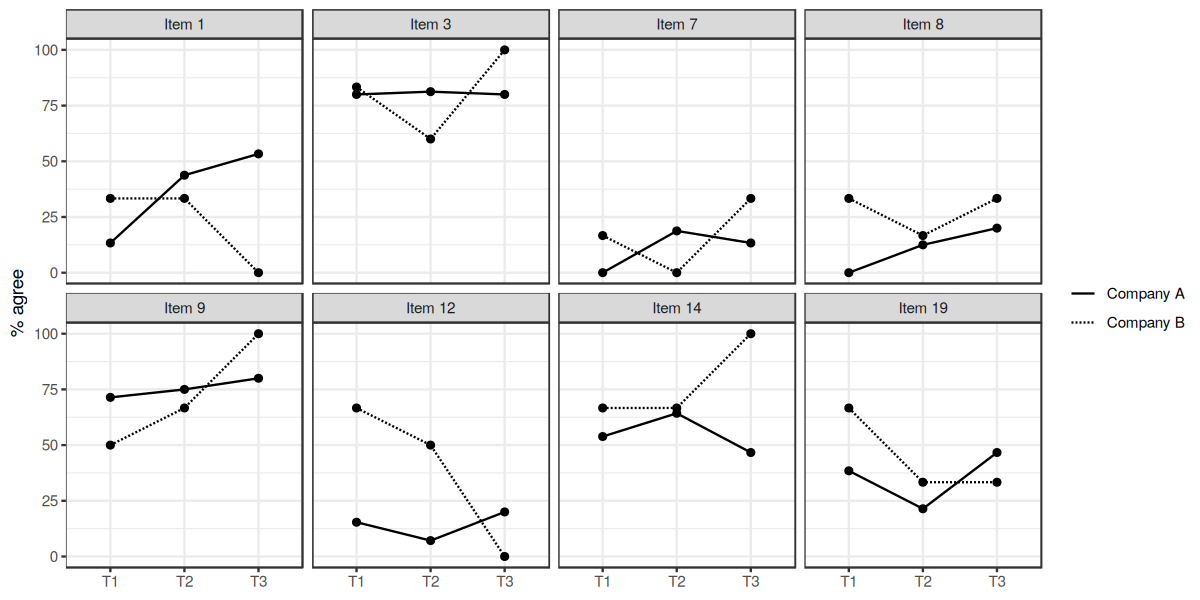

In [11]:
options(repr.plot.width = 10, repr.plot.height = 5)

df |>
  filter(instrument == "lideres") |>
  summarise(pct = 100 * mean(code_3 == 3), .by = c(company, item, wave)) |>
  mutate(company = if_else(company == "finx", "Company A", "Company B")) |>
  ggplot(aes(x = wave, y = pct, group = company, linetype = company)) +
  geom_line() +
  geom_point() +
  facet_wrap(~ item, nrow = 2, labeller = as_labeller(\(x) paste("Item", x))) +
  scale_y_continuous(limits = c(0, 100)) +
  labs(x = NULL, y = "% agree", linetype = NULL) +
  theme_bw()

# Figure 2. Employees: frequency by item and wave

Percentage answering muitas vezes or sempre (often or always) to each stable employee item, by wave and company (Company A = FINX, Company B = Xforce).

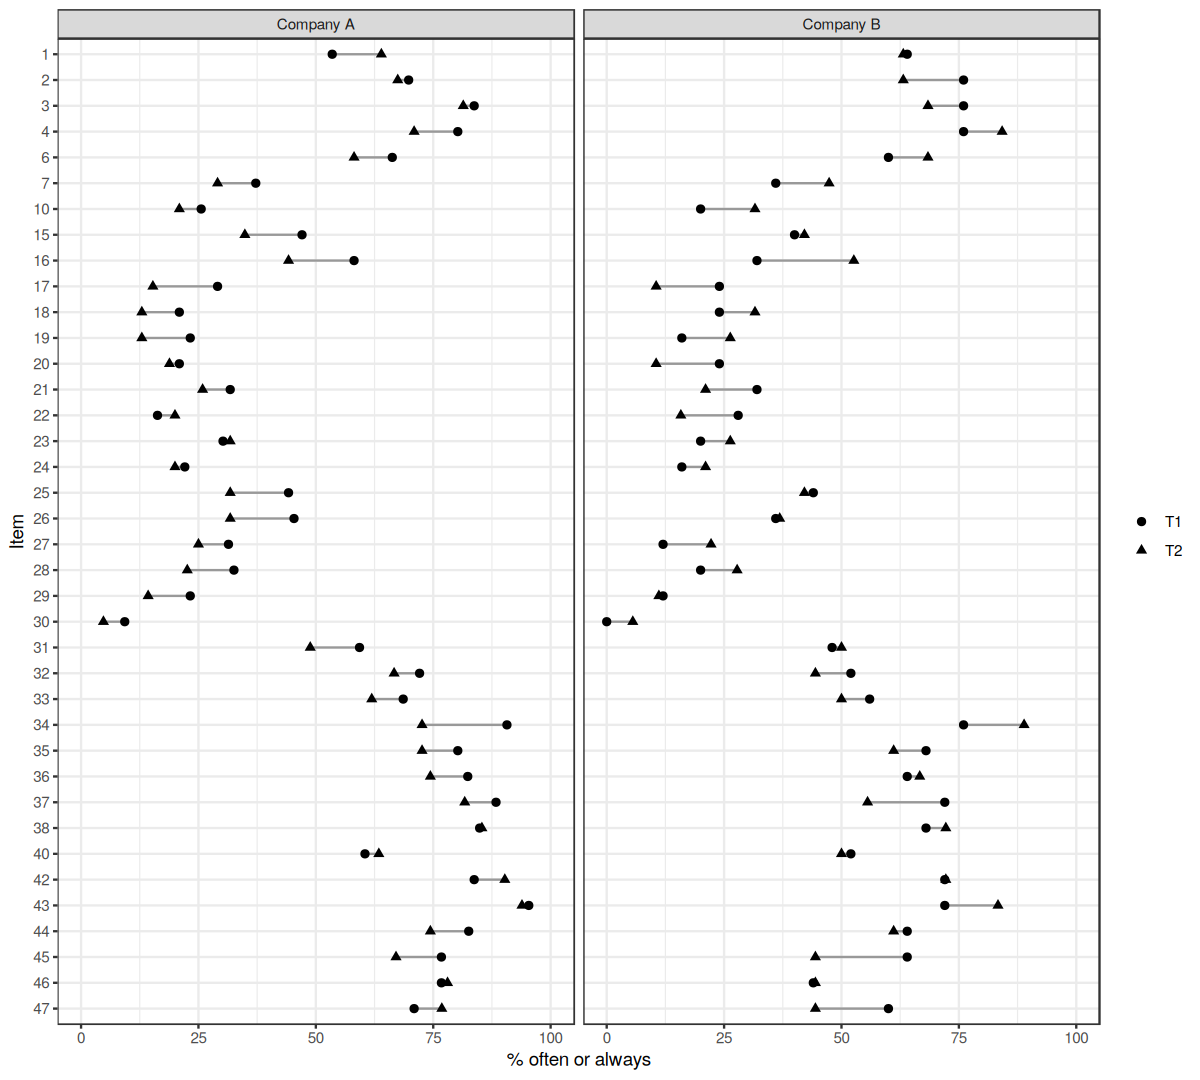

In [12]:
options(repr.plot.width = 10, repr.plot.height = 9)

df |>
  filter(instrument == "emocional", item != 57) |>
  summarise(pct = 100 * mean(code_3 == 3), .by = c(company, item, wave)) |>
  mutate(company = if_else(company == "finx", "Company A", "Company B")) |>
  ggplot(aes(x = pct, y = factor(item, levels = sort(unique(item), decreasing = TRUE)), shape = wave)) +
  geom_line(aes(group = item), colour = "grey60") +
  geom_point(size = 2) +
  facet_wrap(~ company) +
  scale_x_continuous(limits = c(0, 100)) +
  labs(x = "% often or always", y = "Item", shape = NULL) +
  theme_bw()